Madeline Griffiths
11/15/2026
Analysis Report

## Part 1: Select and Explore a Dataset

## Info about dataset
The dataset I chose is the European Countries JSON Dataset: https://jsonlint.com/datasets/european-countries

I mainly chose this dataset because it met the criteria for the assignment (namely, the number of quantitative variables). I also chose it because I believe that the amount of categorical variables will allow me more possibilities with visualization.

Each observation represents a European country and the information about it. It includes info like: the name, the capital, the size of the country (in km^2), the currency it uses, and the population.
The variables I plan to use are: country, region, population, and country size.

The research question I developed is: Does the size of the country affect the size of a European country's population?
The hypothesis is: The larger the European country, the higher its population will be.

In [78]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.formula.api import ols

In [29]:
with open('european-countries.json', 'r', encoding='utf-8') as file:
    data = json.load(file)

#creates dataframe from within 'countries' label
df = pd.DataFrame(data['countries'])
df.head()

,name,code,capital,population,area_km2,eu_member,currency
0,Albania,AL,Tirana,2877797,28748.0,False,ALL
1,Andorra,AD,Andorra la Vella,77265,468.0,False,EUR
2,Austria,AT,Vienna,9006398,83879.0,True,EUR
3,Belarus,BY,Minsk,9449323,207600.0,False,BYN
4,Belgium,BE,Brussels,11589623,30528.0,True,EUR


I see no reasons to edit the data in any way. The json file was pretty simple to convert to a dataframe

## Part 2: Explore Data with Visualizations

### NOTE:
The following will also cover Part 3 of this assignment. For all of the graphs, I have included labels to help viewers understand what the numbers are referring to. I have also changed figure sizes for the charts to give them a neat presentation.

### Histogram

Text(0, 0.5, 'Number of European countries')

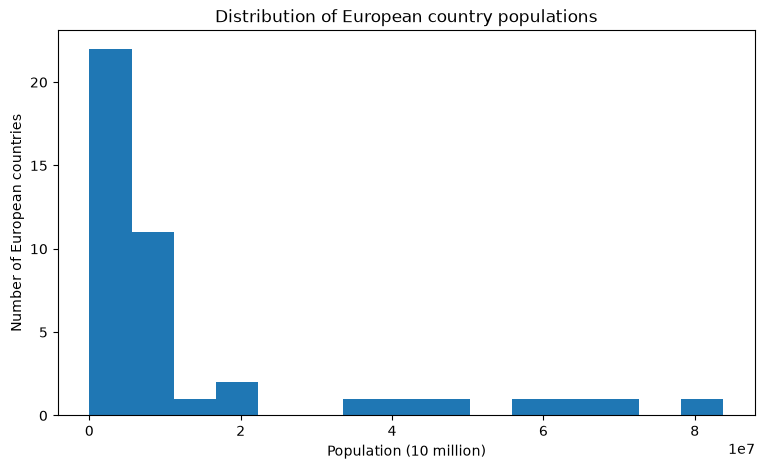

In [58]:
plt.figure(figsize=(9,5))

country_pop = df['population']
plt.hist(country_pop, bins=15)

plt.title('Distribution of European country populations')
plt.xlabel('Population (10 million)')
plt.ylabel('Number of European countries')

#### About the data
The distribution shows that most European countries have a population of under 20,000,000. Very few have over that. Only one country has a population size of over 80,000,000 people. My choice of bins affects the visualization by showing me the missing population gaps. For example, there is a gap between a little after 20,000,000 and before 40,000,000 people.

#### About the visualization
For the x axis label, I chose to specify that the population is by 10 million. That way, if viewers do not know how to read the scientific notation on the right side (1e7), they are still able to understand what the axis is displaying.

### Scatter Plot

In order to create the linear regression line, I followed this website as a guide:
https://www.geeksforgeeks.org/data-visualization/how-to-draw-a-line-inside-a-scatter-plot/

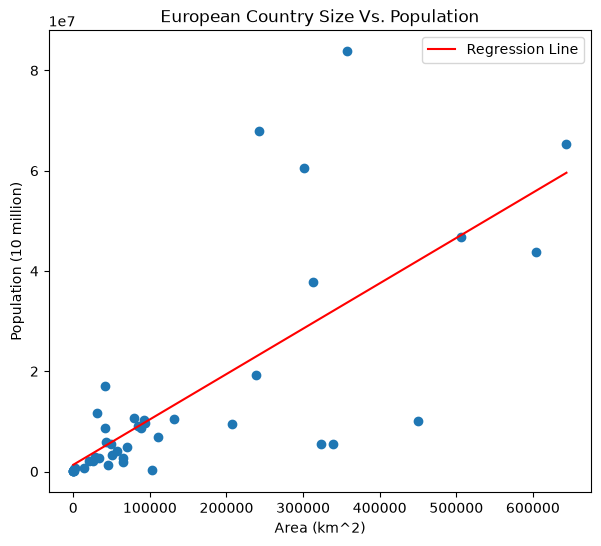

In [79]:
plt.figure(figsize=(7,6))

#linear regression line
#calculating line
slope, intercept = np.polyfit(df['area_km2'], df['population'], 1)
line = slope * df['area_km2'] + intercept

#scatter plot
plt.scatter(
    df['area_km2'],
    df['population']
)

#sort values so linear regression line follows data
df_sorted = df.sort_values('area_km2')
line_sorted = slope * df_sorted['area_km2'] + intercept
plt.plot(df_sorted['area_km2'], line_sorted, color='red', label='Regression Line')
    

plt.title('European Country Size Vs. Population')
plt.xlabel('Area (km^2)')
plt.ylabel('Population (10 million)')
plt.legend()
plt.show()

#### About the data
The chart above seems to show a positive correlation between population size and country size. However, how strong of a correlation is hard to determine due to the lack of an r^2 value.

#### About the visualization
For the same reasons as in the histogram, I chose to specify that the population axis is by 10 million people. Two other things I added is a linear regression line (to display how strong the correlation between the two variables are) and a legend so people know what the line is for.

### Boxplot

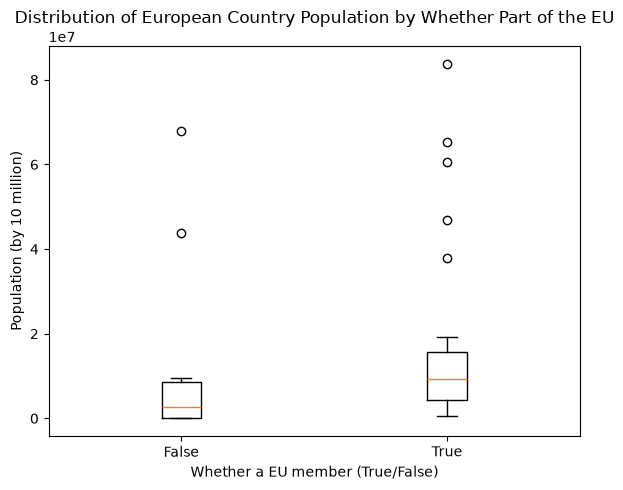

In [77]:
#x axis is going to be currency type
#(some countries use Euros as currency. Others do not)
members = df['eu_member'].unique()

pop_member = [
    df.loc[df['eu_member'] == member, 'population']
    for member in members
]

plt.figure(figsize=(6,5))
plt.boxplot(pop_member, tick_labels=members)

plt.title('Distribution of European Country Population by Whether Part of the EU')
plt.xlabel('Whether a EU member (True/False)')
plt.ylabel("Population (by 10 million)")
plt.tight_layout()
plt.show()

#### About the data
The pattern that can be observed from this boxplot is that countries who are part of the European Union have a wider distribution of populations that, on average, are higher than non-members. This visualization does not take into account what could be the exact cause of the higher populations. Does being an EU member lead to higher populations or are mainly countries with already higher populations joining the EU?

#### About the visualization
I chose to name the tick labels for easier visual clarity for the viewer.

## Part 4: Statistical Analysis

### Investigate a relationship

- Variables compared: Population, country size

In [80]:
model_a = ols(
    'population ~ area_km2',
    data=df
).fit()

print(model_a.summary())

                            OLS Regression Results                            
Dep. Variable:             population   R-squared:                       0.532
Model:                            OLS   Adj. R-squared:                  0.520
Method:                 Least Squares   F-statistic:                     46.55
Date:                Sun, 15 Nov 2026   Prob (F-statistic):           2.93e-08
Time:                        14:45:44   Log-Likelihood:                -769.28
No. Observations:                  43   AIC:                             1543.
Df Residuals:                      41   BIC:                             1546.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1.343e+06   2.89e+06      0.465      0.6

In [82]:
print("r^2:", model_a.rsquared)

r^2: 0.5317104881009243


According to the analysis done using OLS, 53.2% of the variation in the population values is influenced by the size of the European country. This supports my hypothesis of the same thing. The size does not have a complete influence on the population, however. That is why only 53.2% of the variation can be explained by it.

## Part 5: Conclusions and Reflection

What I learned from analyzing my dataset is that there is a positive correlation between population size and country size. This proves my original hypothesis. The visualization type that helped me the most with this was the scatter plot. This is because a scatterplot allows for a visualization of the correlation and the ability to add a linear regression line.

A limitation with this dataset is that it does not allow me to confirm what factors go into a country's population size. I have proved that the size of a country influences it, but only 53.2% of it can be explained by it. What are the other factors? Maybe the GDP of a European country also influenced population size?